# Bagian B — Eksperimen Praktik
**Advanced CNNs and Transfer Learning · Sesi 05 · Bobot 40%**

Notebook ini menjalankan eksperimen ResNet-18 pada 10 kelas Oxford-IIIT Pet.
Semua angka hasil dibuat saat kode dijalankan. Tidak ada hasil eksperimen contoh.
Interpretasi hasil dan kesimpulan harus Anda tulis sendiri setelah memeriksa log.

**Cara mulai:** unggah notebook ke Google Colab, pilih **Runtime → Change runtime type → T4 GPU**,
lalu jalankan sel berurutan. Untuk sesi pertama, berhenti pada **Checkpoint manusia 1**
untuk memeriksa pembagian data dan contoh augmentasi. Setelah itu lanjutkan eksperimen.

| Kondisi | Inisialisasi dan parameter aktif | Augmentasi |
|---|---|---|
| B1 | ResNet-18 acak, semua parameter | Aktif |
| B2 | ImageNet, hanya `fc` | Aktif |
| B3 | ImageNet, `fc` selama 2 epoch, lalu `layer4` + `fc` | Aktif |
| B4 | B2 sebagai pasangan dengan augmentasi, satu run baru tanpa augmentasi | Pembanding nonaktif |

B4 menggunakan kembali bukti run B2 dengan augmentasi, bukan menganggapnya sebagai
replikasi independen. Run B2 tanpa augmentasi dimulai dari bobot dan seed yang sama.
B5 bersifat bonus dan belum dijalankan. B3 menambahkan tahap head-only sebelum
membuka `layer4`, sebagai implementasi progressive fine-tuning (slide 16).

**Titik keterlibatan Anda:** otorisasi Drive bila dipakai; periksa data/augmentasi;
pahami parameter aktif dan BatchNorm; tulis interpretasi dan disclosure bantuan AI.


## 1  Lingkungan dan penyimpanan
Colab biasanya menyediakan pustaka berikut. Sel ini mempertahankan pasangan torch/torchvision
bawaan agar tidak mengubah instalasi GPU. Jika import gagal, gunakan runtime Colab baru.
Unduhan Oxford-IIIT Pet mencakup arsip dataset penuh walaupun hanya 10 kelas digunakan.
Drive menyimpan log/checkpoint ketika runtime berakhir; login dan otorisasi dilakukan oleh Anda.


In [1]:
import os
os.environ['CUBLAS_WORKSPACE_CONFIG'] = ':4096:8'

import copy
import hashlib
import importlib.metadata
import json
import random
import shutil
import sys
import time
import uuid
from datetime import datetime
from pathlib import Path
from zoneinfo import ZoneInfo

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from PIL import Image
import torch
from torch import nn
from torch.utils.data import Dataset, DataLoader, TensorDataset
import torchvision
from torchvision import datasets, models, transforms
from IPython.display import display

DEVICE = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
print('Python:', sys.version.split()[0])
print('PyTorch:', torch.__version__, '| torchvision:', torchvision.__version__)
print('Device:', DEVICE)
if DEVICE.type == 'cuda':
    print('GPU:', torch.cuda.get_device_name(0))
else:
    print('CPU terdeteksi. Pilih runtime T4 sebelum menjalankan eksperimen penuh.')


Python: 3.13.15
PyTorch: 2.11.0+cu130 | torchvision: 0.26.0+cu130
Device: cuda
GPU: Tesla T4


In [2]:
SAVE_TO_DRIVE = True
IN_COLAB = 'google.colab' in sys.modules or Path('/content').exists()
if IN_COLAB and SAVE_TO_DRIVE:
    from google.colab import drive
    drive.mount('/content/drive')
    OUTPUT_ROOT = Path('/content/drive/MyDrive/DeepLearning_Sesi05')
else:
    OUTPUT_ROOT = Path('/content/bagian_b_runs' if IN_COLAB else './bagian_b_runs')

# Menjalankan kembali sel ini membuat sesi baru; log sesi lama tidak ditimpa.
RUN_ID = datetime.now(ZoneInfo('Asia/Bangkok')).strftime('%Y%m%d_%H%M%S') + '_' + uuid.uuid4().hex[:6]
RUN_DIR = OUTPUT_ROOT / RUN_ID
RUN_DIR.mkdir(parents=True, exist_ok=False)
DATA_ROOT = Path('/content/data' if IN_COLAB else './data')
print('Folder hasil:', RUN_DIR)


Mounted at /content/drive
Folder hasil: /content/drive/MyDrive/DeepLearning_Sesi05/20261006_185306_5c1ead


## 2  Protokol yang ditetapkan sebelum eksperimen
Gunakan konfigurasi yang sama untuk setiap kondisi. Seed tetap membantu reproduksibilitas,
tetapi hasil lintas perangkat/versi pustaka belum tentu identik [3]. Ras dipilih sebelum
melihat performa, bukan berdasarkan kelas yang mudah diklasifikasikan.

Early stopping menggunakan validation loss, patience 4, maksimum 30 epoch termasuk
warmup B3. `best_epoch` adalah epoch dengan validation loss minimum; `epochs_run`
adalah jumlah epoch yang benar-benar dijalankan. Mencapai batas 30 epoch tidak otomatis
berarti konvergen. Test set hanya digunakan setelah semua pelatihan dan pemilihan model selesai.


In [3]:
SEED = 42
BATCH_SIZE = 32
MAX_EPOCHS = 30
PATIENCE = 4
WARMUP_EPOCHS = 2
HEAD_LR = 1e-3
BACKBONE_LR = 1e-4
WEIGHT_DECAY = 1e-2
NUM_WORKERS = 2 if IN_COLAB else 0
CLASSES = [
    'Abyssinian', 'Bengal', 'Birman', 'Bombay', 'British_Shorthair',
    'american_bulldog', 'beagle', 'boxer', 'chihuahua', 'english_cocker_spaniel',
]
N_CLASSES = len(CLASSES)
WEIGHTS = models.ResNet18_Weights.IMAGENET1K_V1
EVAL_TRANSFORM = WEIGHTS.transforms()
AUG_TRANSFORM = transforms.Compose([
    transforms.Resize(256),
    transforms.RandomResizedCrop(224, scale=(0.8, 1.0)),
    transforms.RandomHorizontalFlip(p=0.5),
    transforms.RandomRotation(15),
    transforms.ColorJitter(brightness=0.2, contrast=0.2),
    transforms.ToTensor(),
    transforms.Normalize(mean=EVAL_TRANSFORM.mean, std=EVAL_TRANSFORM.std),
])

def seed_everything(seed):
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)
    if torch.cuda.is_available():
        torch.cuda.manual_seed_all(seed)
    torch.backends.cudnn.benchmark = False
    torch.backends.cudnn.deterministic = True
    torch.use_deterministic_algorithms(True)

def save_json(path, value):
    path = Path(path)
    temp = path.with_suffix(path.suffix + '.tmp')
    temp.write_text(json.dumps(value, indent=2, ensure_ascii=False), encoding='utf-8')
    temp.replace(path)

seed_everything(SEED)
CONFIG = dict(seed=SEED, batch_size=BATCH_SIZE, max_epochs=MAX_EPOCHS,
              patience=PATIENCE, warmup_epochs_b3=WARMUP_EPOCHS,
              head_lr=HEAD_LR, backbone_lr=BACKBONE_LR, weight_decay=WEIGHT_DECAY,
              classes=CLASSES, split_ratio=[0.70, 0.15, 0.15],
              optimizer='AdamW', loss='CrossEntropyLoss', precision='float32',
              pretrained_weights='ResNet18_Weights.IMAGENET1K_V1',
              augmentation=repr(AUG_TRANSFORM), evaluation=repr(EVAL_TRANSFORM),
              frozen_batchnorm='eval mode', num_workers=NUM_WORKERS,
              best_checkpoint='minimum validation loss',
              b4_pair=['B2_aug', 'B4_B2_noaug'])
save_json(RUN_DIR / 'config.json', CONFIG)
environment = {name: importlib.metadata.version(name)
               for name in ['torch', 'torchvision', 'numpy', 'pandas', 'matplotlib', 'Pillow']}
environment.update(python=sys.version, cuda=torch.version.cuda,
                   gpu=torch.cuda.get_device_name(0) if DEVICE.type == 'cuda' else None)
save_json(RUN_DIR / 'environment.json', environment)
(RUN_DIR / 'requirements_actual.txt').write_text('\n'.join(
    f'{name}=={environment[name]}' for name in ['torch', 'torchvision', 'numpy', 'pandas', 'matplotlib', 'Pillow']
), encoding='utf-8')
display(pd.DataFrame([CONFIG]).drop(columns=['augmentation', 'evaluation']))


,seed,batch_size,max_epochs,patience,warmup_epochs_b3,head_lr,backbone_lr,weight_decay,classes,split_ratio,optimizer,loss,precision,pretrained_weights,frozen_batchnorm,num_workers,best_checkpoint,b4_pair
0,42,32,30,4,2,0.001,0.0001,0.01,"[Abyssinian, Bengal, Birman, Bombay, British_S...","[0.7, 0.15, 0.15]",AdamW,CrossEntropyLoss,float32,ResNet18_Weights.IMAGENET1K_V1,eval mode,2,minimum validation loss,"[B2_aug, B4_B2_noaug]"


## 3  Data dan pembagian stratified
Dataset resmi menyediakan split `trainval` dan `test`. Untuk memenuhi instruksi tugas
sekitar 2.000 citra dengan split internal 70/15/15, kita menggabungkan kedua daftar resmi,
memilih 10 kelas, lalu membuat split internal baru. Ini bukan evaluasi benchmark dengan
test resmi Oxford. Keanggotaan split baru disimpan di `split_manifest.csv`.

File gambar diverifikasi, duplikat byte-identik dibuang sebelum split, dan jumlah per kelas
dicatat. Pemeriksaan hash tidak mendeteksi semua near-duplicate visual. Tidak ada augmentasi
sebelum pembagian data. Jumlah dibulatkan per kelas sehingga rasio total bisa sedikit berbeda.


In [4]:
_ = datasets.OxfordIIITPet(root=str(DATA_ROOT), split='trainval', download=True)
PET_ROOT = DATA_ROOT / 'oxford-iiit-pet'
records = []
for official_split in ['trainval', 'test']:
    lines = (PET_ROOT / 'annotations' / f'{official_split}.txt').read_text().splitlines()
    for line in lines:
        if not line.strip() or line.startswith('#'):
            continue
        image_id, original_label, species, species_breed = line.split()
        breed = image_id.rsplit('_', 1)[0]
        if breed in CLASSES:
            path = PET_ROOT / 'images' / f'{image_id}.jpg'
            with Image.open(path) as im:
                im.verify()
            records.append(dict(image_id=image_id, breed=breed, label=CLASSES.index(breed),
                                species=int(species), official_split=official_split,
                                sha256=hashlib.sha256(path.read_bytes()).hexdigest()))
frame = pd.DataFrame(records).sort_values('image_id').reset_index(drop=True)
assert set(frame.breed) == set(CLASSES), 'Kelas yang dipilih tidak lengkap.'
assert frame.image_id.is_unique, 'Nama citra ganda di daftar anotasi.'
assert frame.groupby('breed').species.nunique().eq(1).all()
assert frame.groupby('breed').species.first().value_counts().to_dict() == {1: 5, 2: 5}
assert frame.groupby('sha256').label.nunique().max() == 1, 'Duplikat memiliki label berbeda.'
duplicates = frame[frame.duplicated('sha256', keep='first')]
duplicates.to_csv(RUN_DIR / 'excluded_exact_duplicates.csv', index=False)
frame = frame.drop_duplicates('sha256').reset_index(drop=True)

def stratified_split(data, seed):
    result = data.copy()
    result['split'] = ''
    rng = np.random.default_rng(seed)
    for label, group in result.groupby('label', sort=True):
        indices = rng.permutation(group.index.to_numpy())
        n_train, n_val = round(0.70 * len(indices)), round(0.15 * len(indices))
        assert min(n_train, n_val, len(indices) - n_train - n_val) > 0
        result.loc[indices[:n_train], 'split'] = 'train'
        result.loc[indices[n_train:n_train + n_val], 'split'] = 'val'
        result.loc[indices[n_train + n_val:], 'split'] = 'test'
    return result

manifest = stratified_split(frame, SEED)
assert manifest.groupby('sha256').split.nunique().max() == 1
assert manifest.groupby('label').split.nunique().eq(3).all()
manifest.to_csv(RUN_DIR / 'split_manifest.csv', index=False)
MANIFEST_HASH = hashlib.sha256((RUN_DIR / 'split_manifest.csv').read_bytes()).hexdigest()
save_json(RUN_DIR / 'dataset_audit.json', dict(
    selected_before_dedup=len(records), excluded_exact_duplicates=len(duplicates),
    used=len(manifest), manifest_sha256=MANIFEST_HASH))
counts = pd.crosstab(manifest.breed, manifest.split)[['train', 'val', 'test']]
counts.loc['TOTAL'] = counts.sum()
display(counts)
print('SHA256 manifest:', MANIFEST_HASH)


100%|██████████| 792M/792M [00:38<00:00, 20.6MB/s]
100%|██████████| 19.2M/19.2M [00:01<00:00, 10.0MB/s]


split,train,val,test
breed,,,
Abyssinian,139,30,29
Bengal,140,30,30
Birman,140,30,30
Bombay,129,28,27
British_Shorthair,140,30,30
american_bulldog,140,30,30
beagle,140,30,30
boxer,139,30,30
chihuahua,140,30,30


SHA256 manifest: f17c05d6e33de2d3ce14a3d5b651827700fa5252efa11080b426ee56ee21079f


In [5]:
class PetSubset(Dataset):
    def __init__(self, rows, transform):
        self.rows = rows.reset_index(drop=True).copy()
        self.transform = transform

    def __len__(self):
        return len(self.rows)

    def __getitem__(self, index):
        row = self.rows.iloc[index]
        with Image.open(PET_ROOT / 'images' / f'{row.image_id}.jpg') as image:
            x = self.transform(image.convert('RGB'))
        return x, int(row.label)

def seed_worker(worker_id):
    worker_seed = torch.initial_seed() % (2 ** 32)
    np.random.seed(worker_seed)
    random.seed(worker_seed)

def make_loader(split, augment=False, shuffle=False, seed=SEED):
    assert not augment or split == 'train', 'Augmentasi hanya untuk train.'
    dataset = PetSubset(manifest[manifest.split == split], AUG_TRANSFORM if augment else EVAL_TRANSFORM)
    return DataLoader(dataset, batch_size=BATCH_SIZE, shuffle=shuffle,
                      num_workers=NUM_WORKERS, pin_memory=DEVICE.type == 'cuda',
                      worker_init_fn=seed_worker,
                      generator=torch.Generator().manual_seed(seed), drop_last=False)


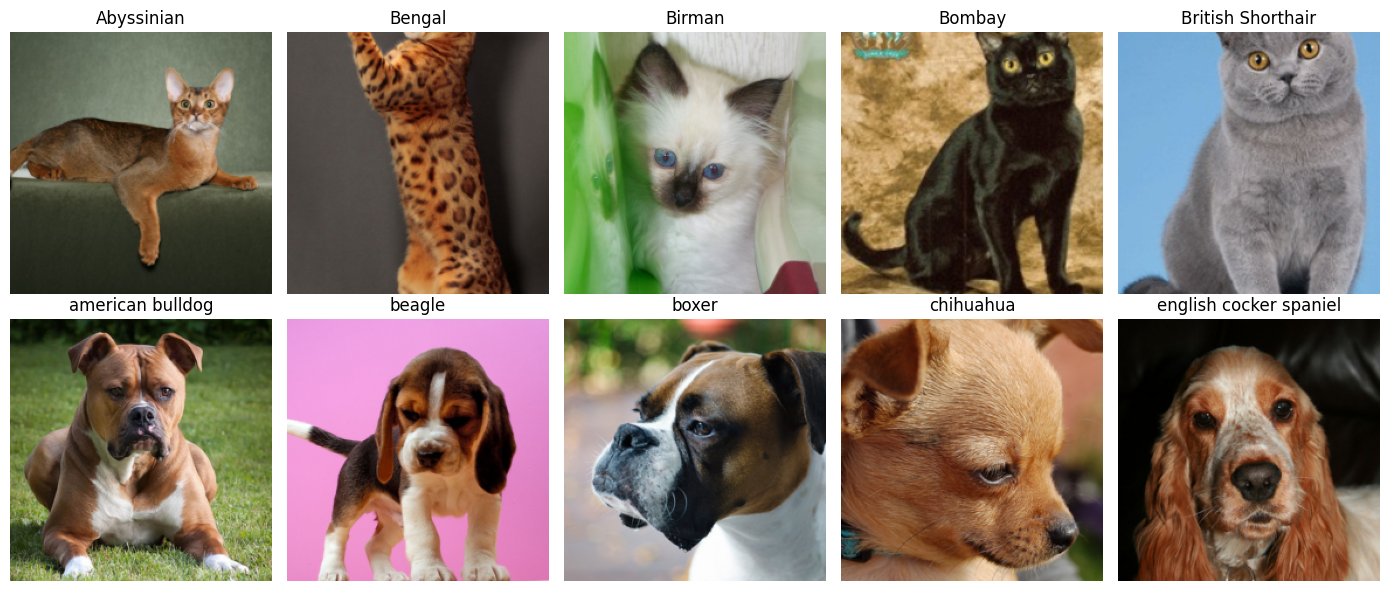

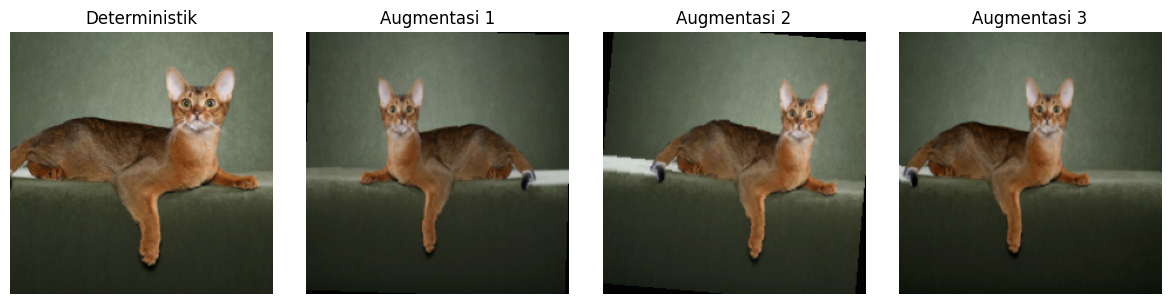

In [6]:
seed_everything(SEED)
fig, axes = plt.subplots(2, 5, figsize=(14, 6))
mean = torch.tensor(EVAL_TRANSFORM.mean)[:, None, None]
std = torch.tensor(EVAL_TRANSFORM.std)[:, None, None]
for label, ax in enumerate(axes.flat):
    row = manifest[(manifest.split == 'train') & (manifest.label == label)].iloc[0]
    with Image.open(PET_ROOT / 'images' / f'{row.image_id}.jpg') as image:
        x = EVAL_TRANSFORM(image.convert('RGB'))
    ax.imshow((x * std + mean).clamp(0, 1).permute(1, 2, 0))
    ax.set_title(CLASSES[label].replace('_', ' '))
    ax.axis('off')
fig.tight_layout()
fig.savefig(RUN_DIR / 'train_examples.png', dpi=150)
plt.show()

row = manifest[manifest.split == 'train'].iloc[0]
with Image.open(PET_ROOT / 'images' / f'{row.image_id}.jpg') as image:
    original = image.convert('RGB')
fig, axes = plt.subplots(1, 4, figsize=(12, 3))
for i, ax in enumerate(axes):
    x = EVAL_TRANSFORM(original) if i == 0 else AUG_TRANSFORM(original)
    ax.imshow((x * std + mean).clamp(0, 1).permute(1, 2, 0))
    ax.set_title('Deterministik' if i == 0 else f'Augmentasi {i}')
    ax.axis('off')
fig.tight_layout()
fig.savefig(RUN_DIR / 'augmentation_examples.png', dpi=150)
plt.show()


1. Keterwakilan Kelas pada Split dan Masalah Gambar

  Keterwakilan: Ya, kelima ras kucing (Abyssinian, Bengal, Birman, Bombay, British Shorthair) dan kelima ras anjing (American Bulldog, Beagle, Boxer, Chihuahua, English Cocker Spaniel) terwakili di setiap split. Hal ini dijamin oleh fungsi stratified_split pada kode yang membagi proporsi 70/15/15 secara merata untuk setiap grup label.

Temuan Masalah (Penting): Berdasarkan visualisasi pada image_78783f.jpg, gambar contoh untuk ras kucing Bengal bermasalah. Gambar tersebut terpotong terlalu ekstrem (zoom-in atau cropping yang salah) sehingga hanya menampilkan bagian kaki dan batang tubuh tanpa memperlihatkan kepala atau fitur wajah kucing. Sesuai instruksi checkpoint, ini harus diperbaiki sebelum training (misalnya dengan membuang gambar yang rusak tersebut atau memperbaiki parameter cropping) agar model tidak mempelajari fitur yang salah.

2. Efektivitas Augmentasi
Ya, augmentasi masih mempertahankan ciri ras dengan baik. Berdasarkan gambar contoh kucing Abyssinian di baris paling bawah pada image_78783f.jpg, hasil transformasi (Augmentasi 1, 2, dan 3) hanya mengubah orientasi spasial seperti horizontal flip, rotasi ringan, dan variasi pencahayaan. Ciri utama penentu ras seperti warna bulu, bentuk telinga yang runcing, dan postur tubuh tetap utuh dan sangat mudah dikenali oleh mata manusia maupun model.

3. Alasan Split Harus Dilakukan Sebelum Augmentasi
Pemisahan data (split) mutlak harus dilakukan sebelum augmentasi untuk mencegah kebocoran data (data leakage). Jika dataset diaugmentasi terlebih dahulu lalu dipecah secara acak, ada kemungkinan sangat besar sebuah gambar asli masuk ke set train, sementara versi augmentasinya (gambar yang sama namun dirotasi/di-flip) masuk ke set validation atau test. Akibatnya, model seolah-olah memiliki akurasi yang tinggi saat divalidasi karena model hanya mengingat gambar yang sudah ia lihat, bukan belajar melakukan generalisasi pada gambar yang benar-benar baru.

## 4  Model dan pembekuan lapisan
`requires_grad=False` membekukan parameter tetapi tidak membekukan running statistics
BatchNorm. Karena itu B2 memakai backbone dalam mode `eval`, sedangkan B3 hanya
mengaktifkan mode training untuk `layer4` setelah warmup dan untuk `fc`.

Head menggunakan inisialisasi seed yang sama pada semua kondisi. B1 tetap mempunyai
backbone acak. Pada B3, optimizer mempertahankan state head ketika `layer4` ditambahkan.
Learning rate tetap, dengan grup head 0,001 dan grup layer4 0,0001.


In [7]:
def build_model(strategy, pretrained=True):
    assert strategy in {'scratch', 'feature', 'progressive'}
    seed_everything(SEED)
    weights = WEIGHTS if pretrained and strategy != 'scratch' else None
    model = models.resnet18(weights=weights)
    torch.manual_seed(SEED + 1)
    model.fc = nn.Linear(model.fc.in_features, N_CLASSES)
    for name, param in model.named_parameters():
        param.requires_grad = strategy == 'scratch' or name.startswith('fc.')
    return model

def set_training_mode(model, strategy, stage):
    if strategy == 'scratch':
        model.train()
    else:
        model.eval()
        model.fc.train()
        if strategy == 'progressive' and stage == 'layer4':
            model.layer4.train()

def trainable_count(model):
    return sum(p.numel() for p in model.parameters() if p.requires_grad)

def make_optimizer(model, strategy):
    group_name = 'all' if strategy == 'scratch' else 'fc'
    params = [p for p in model.parameters() if p.requires_grad]
    return torch.optim.AdamW([dict(params=params, lr=HEAD_LR, name=group_name)],
                             weight_decay=WEIGHT_DECAY)

def unfreeze_layer4(model, optimizer):
    for p in model.layer4.parameters():
        p.requires_grad = True
    optimizer.add_param_group(dict(params=model.layer4.parameters(), lr=BACKBONE_LR, name='layer4'))

def classification_metrics(y_true, y_pred, n_classes=N_CLASSES):
    # Baris = label aktual, kolom = prediksi; seluruh kelas ikut rata-rata Macro F1.
    y_true, y_pred = np.asarray(y_true), np.asarray(y_pred)
    assert len(y_true) == len(y_pred) and len(y_true) > 0
    cm = np.bincount(n_classes * y_true + y_pred,
                     minlength=n_classes ** 2).reshape(n_classes, n_classes)
    denominator = cm.sum(axis=0) + cm.sum(axis=1)
    f1 = np.divide(2 * cm.diagonal(), denominator,
                   out=np.zeros(n_classes, dtype=float), where=denominator != 0)
    return dict(accuracy=float(cm.trace() / cm.sum()), macro_f1=float(f1.mean()))


## 5  Pemeriksaan kode sebelum training
Ini adalah tes mekanisme dengan tensor sintetis, bukan hasil eksperimen Oxford-IIIT Pet.
Tes memeriksa bahwa update B2 hanya mengubah head, termasuk memeriksa buffer BatchNorm;
B3 mengubah layer4 setelah unfreeze tetapi tetap melindungi bagian backbone sebelumnya.


In [8]:
def self_check():
    old_threads = torch.get_num_threads()
    torch.set_num_threads(min(2, old_threads))
    try:
        assert classification_metrics([0, 0, 1, 1], [0, 1, 1, 1], 2)['macro_f1'] == (2/3 + 4/5)/2
        toy = pd.DataFrame({'label': [0] * 20 + [1] * 20, 'image_id': range(40)})
        split = stratified_split(toy, SEED)
        assert split.equals(stratified_split(toy, SEED))
        assert pd.crosstab(split.label, split.split).to_dict() == {
            'test': {0: 3, 1: 3}, 'train': {0: 14, 1: 14}, 'val': {0: 3, 1: 3}}
        x, y = torch.randn(2, 3, 64, 64), torch.tensor([0, 1])
        for strategy in ['scratch', 'feature', 'progressive']:
            model = build_model(strategy, pretrained=False)
            optimizer = make_optimizer(model, strategy)
            if strategy == 'scratch':
                assert trainable_count(model) == sum(p.numel() for p in model.parameters())
            else:
                assert trainable_count(model) == 5130
            stage = 'head'
            if strategy == 'progressive':
                unfreeze_layer4(model, optimizer)
                stage = 'layer4'
                assert all(p.requires_grad == (n.startswith('fc.') or n.startswith('layer4.'))
                           for n, p in model.named_parameters())
            before = {n: t.clone() for n, t in model.state_dict().items()}
            set_training_mode(model, strategy, stage)
            optimizer.zero_grad(set_to_none=True)
            logits = model(x)
            assert logits.shape == (2, N_CLASSES)
            nn.CrossEntropyLoss()(logits, y).backward()
            optimizer.step()
            changed = {n for n, t in model.state_dict().items() if not torch.equal(t, before[n])}
            assert 'fc.weight' in changed
            if strategy == 'feature':
                assert all(n.startswith('fc.') for n in changed), changed
            if strategy == 'progressive':
                assert any(n.startswith('layer4.') for n in changed)
                assert all(n.startswith(('fc.', 'layer4.')) for n in changed), changed
            print(strategy, ':', trainable_count(model), 'trainable parameters; check passed')
    finally:
        torch.set_num_threads(old_threads)
        seed_everything(SEED)

self_check()


scratch : 11181642 trainable parameters; check passed
feature : 5130 trainable parameters; check passed
progressive : 8398858 trainable parameters; check passed


**1. Mengapa B2 mempunyai 512 × 10 + 10 = 5.130 parameter yang dilatih?**
Pada kondisi B2 (strategi *feature extraction*), seluruh bobot *backbone* dari ResNet-18 dibekukan, sehingga hanya *layer classifier* terakhir (layer `fc`) yang dipelajari ulang. Layer `fc` pada arsitektur ResNet-18 menerima matriks masukan berukuran 512 (*in_features*) dan dihubungkan ke 10 node *output* sesuai jumlah kelas (*out_features*). Sebuah layer *Linear/Fully Connected* memiliki bobot (*weights*) dan bias.
Perhitungannya adalah: $(512 \times 10) \text{ bobot} + 10 \text{ bias} = 5.130$ parameter. Oleh karena itu, hanya 5.130 parameter ini yang memiliki nilai `requires_grad=True`.

**2. Mengapa membekukan gradien saja belum cukup untuk membekukan BatchNorm?**
Atribut `requires_grad=False` hanya menghentikan perhitungan turunan (*gradient*) pada saat *backward pass* sehingga parameter *affine* ($\gamma$ dan $\beta$) tidak di-update oleh *optimizer*. Namun, layer *Batch Normalization* (BatchNorm) juga menyimpan *running statistics* (rata-rata dan varians dari *batch* data) yang di-update pada saat *forward pass*. Jika kita tidak mengubah mode layer menjadi evaluasi, *running statistics* ini akan terus berubah mengikuti data *training* kita yang baru. Agar pengetahuan dari *pretrained weights* tidak rusak secara tidak sengaja, kita harus secara eksplisit memanggil `model.eval()` agar BatchNorm menggunakan statistik statis yang sudah ada.

**3. Apa yang berubah saat `layer4` dibuka pada B3?**
Pada strategi *progressive fine-tuning* (B3), setelah *warm-up* beberapa *epoch*, `layer4` (blok konvolusi terakhir pada ResNet sebelum *pooling*) akan "dibuka" (*unfrozen*). Perubahan yang terjadi adalah:

* **Aktivasi parameter:** Atribut `requires_grad` pada seluruh bobot di `layer4` diubah menjadi `True`. Ini membuat total parameter yang dilatih melonjak pesat dari 5.130 menjadi 8.398.858 parameter.
* **Perubahan mode:** `model.layer4.train()` dipanggil. Hal ini mengizinkan layer BatchNorm di dalam `layer4` untuk kembali aktif memperbarui *running statistics*-nya khusus untuk dataset baru ini.
* **Penyesuaian *Optimizer*:** Parameter dari `layer4` dimasukkan ke dalam *optimizer* dengan *learning rate* yang spesifik dan lebih kecil (`BACKBONE_LR` = 1e-4) dibanding layer kepala/`fc`, agar bobot konvolusi tidak bergeser terlalu agresif.

In [9]:
def synchronize():
    if DEVICE.type == 'cuda':
        torch.cuda.synchronize()

def train_epoch(model, loader, optimizer, strategy, stage):
    set_training_mode(model, strategy, stage)
    loss_sum, correct, size = 0.0, 0, 0
    for x, y in loader:
        x, y = x.to(DEVICE), y.to(DEVICE)
        optimizer.zero_grad(set_to_none=True)
        logits = model(x)
        loss = nn.functional.cross_entropy(logits, y)
        if not torch.isfinite(loss):
            raise RuntimeError('Loss tidak finite; periksa data dan learning rate.')
        loss.backward()
        optimizer.step()
        loss_sum += loss.item() * len(y)
        correct += (logits.argmax(1) == y).sum().item()
        size += len(y)
    return dict(loss=loss_sum / size, accuracy=correct / size)

@torch.inference_mode()
def evaluate(model, loader):
    model.eval()
    loss_sum, labels, predictions, confidence = 0.0, [], [], []
    for x, y in loader:
        logits = model(x.to(DEVICE))
        loss_sum += nn.functional.cross_entropy(logits, y.to(DEVICE), reduction='sum').item()
        probs, pred = logits.softmax(1).max(1)
        labels.extend(y.tolist())
        predictions.extend(pred.cpu().tolist())
        confidence.extend(probs.cpu().tolist())
    metrics = classification_metrics(labels, predictions)
    metrics['loss'] = loss_sum / len(labels)
    return metrics, pd.DataFrame(dict(label=labels, prediction=predictions, confidence=confidence))

def checkpoint(model, path, **metadata):
    payload = dict(state_dict={k: v.detach().cpu() for k, v in model.state_dict().items()}, **metadata)
    temp = Path(path).with_suffix('.tmp')
    torch.save(payload, temp)
    temp.replace(path)

def fit_experiment(name, strategy, augment):
    folder = RUN_DIR / name
    # Satu folder = satu run; jangan diam-diam menimpa log atau mengulang run selesai.
    folder.mkdir(exist_ok=False)
    save_json(folder / 'status.json', {'status': 'running'})
    model = build_model(strategy).to(DEVICE)
    optimizer = make_optimizer(model, strategy)
    initial_hash = hashlib.sha256(b''.join(t.detach().cpu().numpy().tobytes()
        for t in model.state_dict().values())).hexdigest()
    save_json(folder / 'protocol.json', dict(name=name, strategy=strategy, augmentation=augment,
        config=CONFIG, manifest_sha256=MANIFEST_HASH, initial_state_sha256=initial_hash))
    history, best_loss, best_epoch, bad_epochs = [], float('inf'), None, 0
    stage = 'all' if strategy == 'scratch' else 'head'
    stop_reason = 'max_epochs'
    synchronize()
    wall_start = time.perf_counter()
    for epoch in range(1, MAX_EPOCHS + 1):
        if strategy == 'progressive' and epoch == WARMUP_EPOCHS + 1:
            unfreeze_layer4(model, optimizer)
            stage, bad_epochs = 'layer4', 0
        # Seed per epoch menjaga urutan sampel sama antar kondisi meski transform berbeda.
        seed_everything(SEED + epoch)
        train_loader = make_loader('train', augment=augment, shuffle=True, seed=SEED + epoch)
        synchronize()
        start = time.perf_counter()
        train_opt = train_epoch(model, train_loader, optimizer, strategy, stage)
        synchronize()
        optimization_seconds = time.perf_counter() - start
        train_eval, _ = evaluate(model, make_loader('train'))
        val, _ = evaluate(model, make_loader('val'))
        synchronize()
        compute_seconds = time.perf_counter() - start
        if not np.isfinite(val['loss']):
            raise RuntimeError('Validation loss tidak finite.')
        lrs = {group['name']: group['lr'] for group in optimizer.param_groups}
        row = dict(epoch=epoch, stage=stage, trainable_parameters=trainable_count(model),
                   learning_rates=json.dumps(lrs), train_optimization_loss=train_opt['loss'],
                   train_optimization_accuracy=train_opt['accuracy'],
                   train_eval_loss=train_eval['loss'], train_eval_accuracy=train_eval['accuracy'],
                   val_loss=val['loss'], val_accuracy=val['accuracy'], val_macro_f1=val['macro_f1'],
                   accuracy_gap=train_eval['accuracy'] - val['accuracy'],
                   optimization_seconds=optimization_seconds, compute_seconds=compute_seconds)
        history.append(row)
        if val['loss'] < best_loss:
            best_loss, best_epoch, bad_epochs = val['loss'], epoch, 0
            checkpoint(model, folder / 'best.pt', epoch=epoch, stage=stage,
                       strategy=strategy, trainable_parameters=trainable_count(model),
                       val_loss=best_loss, classes=CLASSES)
        elif strategy != 'progressive' or epoch > WARMUP_EPOCHS:
            bad_epochs += 1
        pd.DataFrame(history).to_csv(folder / 'history.csv', index=False)
        print(f'{name} | epoch {epoch:02d} | {stage:6s} | '
              f'train_eval={train_eval["loss"]:.4f} | val={val["loss"]:.4f} | '
              f'val_acc={val["accuracy"]:.3f}', flush=True)
        if bad_epochs >= PATIENCE:
            stop_reason = 'early_stopping'
            break
    synchronize()
    wall_seconds = time.perf_counter() - wall_start
    selected = history[best_epoch - 1]
    summary = dict(name=name, strategy=strategy, augmentation=augment,
                   total_parameters=sum(p.numel() for p in model.parameters()),
                   trainable_parameters_final=trainable_count(model),
                   trainable_parameters_at_best=selected['trainable_parameters'],
                   learning_rates_at_best=selected['learning_rates'],
                   best_epoch=best_epoch, best_stage=selected['stage'], epochs_run=len(history),
                   stop_reason=stop_reason, best_val_loss=selected['val_loss'],
                   best_val_accuracy=selected['val_accuracy'],
                   train_eval_accuracy_at_best=selected['train_eval_accuracy'],
                   accuracy_gap_at_best=selected['accuracy_gap'],
                   optimization_seconds=sum(r['optimization_seconds'] for r in history),
                   training_and_validation_seconds=sum(r['compute_seconds'] for r in history),
                   wall_seconds_including_checkpoint_io=wall_seconds,
                   initial_state_sha256=initial_hash, manifest_sha256=MANIFEST_HASH)
    save_json(folder / 'summary.json', summary)
    save_json(folder / 'status.json', {'status': 'complete'})
    del model, optimizer
    if DEVICE.type == 'cuda':
        torch.cuda.empty_cache()
    return summary


## 6  Jalankan B1 sampai B4
Setiap sel menjalankan satu kondisi sampai selesai. Semua durasi diukur pada runtime
yang sama. Unduhan bobot dan dataset tidak masuk timer; `optimization_seconds` menghitung
training saja, `training_and_validation_seconds` termasuk evaluasi train/val, dan
`wall_seconds_including_checkpoint_io` juga mencakup penyimpanan ke Drive.

Bila runtime terputus di tengah run, log epoch yang selesai tetap disimpan. Run yang terputus
harus diulang dari awal pada sesi baru dan tidak dianggap selesai. Jangan menggabungkan
sebagian log dari dua run. Pastikan `GPU: Tesla T4` (atau GPU yang dialokasikan) tercatat.


In [10]:
assert DEVICE.type == 'cuda', 'Pilih runtime GPU Colab sebelum training penuh.'
summary_b1 = fit_experiment('B1_scratch_aug', 'scratch', augment=True)
display(pd.DataFrame([summary_b1]))


B1_scratch_aug | epoch 01 | all    | train_eval=2.4381 | val=2.5509 | val_acc=0.215
B1_scratch_aug | epoch 02 | all    | train_eval=1.8535 | val=2.0331 | val_acc=0.283
B1_scratch_aug | epoch 03 | all    | train_eval=2.2253 | val=2.4079 | val_acc=0.226
B1_scratch_aug | epoch 04 | all    | train_eval=1.7916 | val=1.9711 | val_acc=0.343
B1_scratch_aug | epoch 05 | all    | train_eval=2.0921 | val=2.2654 | val_acc=0.300
B1_scratch_aug | epoch 06 | all    | train_eval=1.6388 | val=1.7645 | val_acc=0.394
B1_scratch_aug | epoch 07 | all    | train_eval=2.1492 | val=2.3347 | val_acc=0.310
B1_scratch_aug | epoch 08 | all    | train_eval=1.7855 | val=1.9849 | val_acc=0.306
B1_scratch_aug | epoch 09 | all    | train_eval=1.6293 | val=1.9129 | val_acc=0.343
B1_scratch_aug | epoch 10 | all    | train_eval=1.5950 | val=1.8701 | val_acc=0.380


,name,strategy,augmentation,total_parameters,trainable_parameters_final,trainable_parameters_at_best,learning_rates_at_best,best_epoch,best_stage,epochs_run,stop_reason,best_val_loss,best_val_accuracy,train_eval_accuracy_at_best,accuracy_gap_at_best,optimization_seconds,training_and_validation_seconds,wall_seconds_including_checkpoint_io,initial_state_sha256,manifest_sha256
0,B1_scratch_aug,scratch,True,11181642,11181642,11181642,"{""all"": 0.001}",6,all,10,early_stopping,1.764477,0.393939,0.427746,0.033806,133.6917,237.591378,238.397466,5b7e1c53fbef0ebdc874bec5695978d3518b9867c3f0bf...,f17c05d6e33de2d3ce14a3d5b651827700fa5252efa110...


In [11]:
summary_b2 = fit_experiment('B2_aug', 'feature', augment=True)
display(pd.DataFrame([summary_b2]))


Downloading: "https://download.pytorch.org/models/resnet18-f37072fd.pth" to /root/.cache/torch/hub/checkpoints/resnet18-f37072fd.pth


100%|██████████| 44.7M/44.7M [00:00<00:00, 193MB/s]


B2_aug | epoch 01 | head   | train_eval=0.6104 | val=0.6426 | val_acc=0.916
B2_aug | epoch 02 | head   | train_eval=0.3360 | val=0.3617 | val_acc=0.929
B2_aug | epoch 03 | head   | train_eval=0.2490 | val=0.2784 | val_acc=0.946
B2_aug | epoch 04 | head   | train_eval=0.2065 | val=0.2226 | val_acc=0.946
B2_aug | epoch 05 | head   | train_eval=0.1731 | val=0.1942 | val_acc=0.953
B2_aug | epoch 06 | head   | train_eval=0.1634 | val=0.1787 | val_acc=0.953
B2_aug | epoch 07 | head   | train_eval=0.1473 | val=0.1597 | val_acc=0.946
B2_aug | epoch 08 | head   | train_eval=0.1358 | val=0.1619 | val_acc=0.953
B2_aug | epoch 09 | head   | train_eval=0.1189 | val=0.1468 | val_acc=0.960
B2_aug | epoch 10 | head   | train_eval=0.1163 | val=0.1457 | val_acc=0.953
B2_aug | epoch 11 | head   | train_eval=0.1064 | val=0.1337 | val_acc=0.960
B2_aug | epoch 12 | head   | train_eval=0.1141 | val=0.1320 | val_acc=0.953
B2_aug | epoch 13 | head   | train_eval=0.0919 | val=0.1255 | val_acc=0.956
B2_aug | epo

,name,strategy,augmentation,total_parameters,trainable_parameters_final,trainable_parameters_at_best,learning_rates_at_best,best_epoch,best_stage,epochs_run,stop_reason,best_val_loss,best_val_accuracy,train_eval_accuracy_at_best,accuracy_gap_at_best,optimization_seconds,training_and_validation_seconds,wall_seconds_including_checkpoint_io,initial_state_sha256,manifest_sha256
0,B2_aug,feature,True,11181642,5130,5130,"{""fc"": 0.001}",25,head,29,early_stopping,0.099418,0.96633,0.979046,0.012716,344.658951,644.52249,647.5029,ebd2a72c0d4fbbdcf07eb0acdca1e87485dec82b4eae3d...,f17c05d6e33de2d3ce14a3d5b651827700fa5252efa110...


In [12]:
summary_b3 = fit_experiment('B3_progressive_aug', 'progressive', augment=True)
display(pd.DataFrame([summary_b3]))


B3_progressive_aug | epoch 01 | head   | train_eval=0.6104 | val=0.6426 | val_acc=0.916
B3_progressive_aug | epoch 02 | head   | train_eval=0.3360 | val=0.3617 | val_acc=0.929
B3_progressive_aug | epoch 03 | layer4 | train_eval=0.0870 | val=0.1231 | val_acc=0.970
B3_progressive_aug | epoch 04 | layer4 | train_eval=0.0469 | val=0.1201 | val_acc=0.963
B3_progressive_aug | epoch 05 | layer4 | train_eval=0.0318 | val=0.1308 | val_acc=0.953
B3_progressive_aug | epoch 06 | layer4 | train_eval=0.0374 | val=0.1180 | val_acc=0.960
B3_progressive_aug | epoch 07 | layer4 | train_eval=0.0186 | val=0.1131 | val_acc=0.966
B3_progressive_aug | epoch 08 | layer4 | train_eval=0.0166 | val=0.0968 | val_acc=0.960
B3_progressive_aug | epoch 09 | layer4 | train_eval=0.0143 | val=0.1038 | val_acc=0.960
B3_progressive_aug | epoch 10 | layer4 | train_eval=0.0121 | val=0.1034 | val_acc=0.970
B3_progressive_aug | epoch 11 | layer4 | train_eval=0.0136 | val=0.1363 | val_acc=0.953
B3_progressive_aug | epoch 12 | 

,name,strategy,augmentation,total_parameters,trainable_parameters_final,trainable_parameters_at_best,learning_rates_at_best,best_epoch,best_stage,epochs_run,stop_reason,best_val_loss,best_val_accuracy,train_eval_accuracy_at_best,accuracy_gap_at_best,optimization_seconds,training_and_validation_seconds,wall_seconds_including_checkpoint_io,initial_state_sha256,manifest_sha256
0,B3_progressive_aug,progressive,True,11181642,8398858,8398858,"{""fc"": 0.001, ""layer4"": 0.0001}",8,layer4,12,early_stopping,0.096763,0.959596,0.994942,0.035346,150.334819,276.64089,278.023439,ebd2a72c0d4fbbdcf07eb0acdca1e87485dec82b4eae3d...,f17c05d6e33de2d3ce14a3d5b651827700fa5252efa110...


In [13]:
summary_b4 = fit_experiment('B4_B2_noaug', 'feature', augment=False)
assert summary_b2['initial_state_sha256'] == summary_b4['initial_state_sha256']
assert summary_b2['manifest_sha256'] == summary_b4['manifest_sha256']
display(pd.DataFrame([summary_b4]))


B4_B2_noaug | epoch 01 | head   | train_eval=0.5341 | val=0.5780 | val_acc=0.933
B4_B2_noaug | epoch 02 | head   | train_eval=0.2865 | val=0.3248 | val_acc=0.943
B4_B2_noaug | epoch 03 | head   | train_eval=0.2158 | val=0.2585 | val_acc=0.956
B4_B2_noaug | epoch 04 | head   | train_eval=0.1690 | val=0.2049 | val_acc=0.949
B4_B2_noaug | epoch 05 | head   | train_eval=0.1404 | val=0.1890 | val_acc=0.963
B4_B2_noaug | epoch 06 | head   | train_eval=0.1221 | val=0.1622 | val_acc=0.970
B4_B2_noaug | epoch 07 | head   | train_eval=0.1104 | val=0.1560 | val_acc=0.956
B4_B2_noaug | epoch 08 | head   | train_eval=0.0971 | val=0.1510 | val_acc=0.963
B4_B2_noaug | epoch 09 | head   | train_eval=0.0878 | val=0.1461 | val_acc=0.963
B4_B2_noaug | epoch 10 | head   | train_eval=0.0814 | val=0.1411 | val_acc=0.963
B4_B2_noaug | epoch 11 | head   | train_eval=0.0767 | val=0.1416 | val_acc=0.963
B4_B2_noaug | epoch 12 | head   | train_eval=0.0740 | val=0.1339 | val_acc=0.956
B4_B2_noaug | epoch 13 | hea

,name,strategy,augmentation,total_parameters,trainable_parameters_final,trainable_parameters_at_best,learning_rates_at_best,best_epoch,best_stage,epochs_run,stop_reason,best_val_loss,best_val_accuracy,train_eval_accuracy_at_best,accuracy_gap_at_best,optimization_seconds,training_and_validation_seconds,wall_seconds_including_checkpoint_io,initial_state_sha256,manifest_sha256
0,B4_B2_noaug,feature,False,11181642,5130,5130,"{""fc"": 0.001}",14,head,18,early_stopping,0.117561,0.962963,0.989162,0.026199,147.089996,334.290556,336.422911,ebd2a72c0d4fbbdcf07eb0acdca1e87485dec82b4eae3d...,f17c05d6e33de2d3ce14a3d5b651827700fa5252efa110...


In [17]:
# B5 — EfficientNet-B0 with B3's progressive fine-tuning configuration
B5_NAME = "B5_efficientnet_b0_aug_retry1"
B5_STRATEGY = "efficientnet_b0_progressive"

baseline_names = [
    "B1_scratch_aug",
    "B2_aug",
    "B3_progressive_aug",
    "B4_B2_noaug",
]
baseline_results = [
    json.loads((RUN_DIR / name / "summary.json").read_text())
    for name in baseline_names
]
best_baseline = min(baseline_results, key=lambda r: r["best_val_loss"])

assert best_baseline["name"] == "B3_progressive_aug"
assert best_baseline["manifest_sha256"] == MANIFEST_HASH
assert DEVICE.type == "cuda", "Use the same GPU runtime as B1–B4."
assert not (RUN_DIR / B5_NAME).exists(), "B5 already exists; do not overwrite it."


class EfficientNetForExperiment(nn.Module):
    """Expose fc/layer4 so the existing training loop can be reused."""

    def __init__(self, pretrained=True):
        super().__init__()
        seed_everything(SEED)

        weights = (
            models.EfficientNet_B0_Weights.IMAGENET1K_V1
            if pretrained else None
        )
        base = models.efficientnet_b0(weights=weights)

        self.early = base.features[:-2]

        # Log label "layer4" means EfficientNet features[7:9]:
        # the final MBConv stage and final convolution.
        self.layer4 = base.features[-2:]
        self.avgpool = base.avgpool

        torch.manual_seed(SEED + 1)
        base.classifier[1] = nn.Linear(
            base.classifier[1].in_features, N_CLASSES
        )
        self.fc = base.classifier  # Retains native Dropout(p=0.2).

        for name, parameter in self.named_parameters():
            parameter.requires_grad = name.startswith("fc.")

    def forward(self, x):
        x = self.layer4(self.early(x))
        return self.fc(torch.flatten(self.avgpool(x), 1))


# Quick architecture check; no pretrained download needed here.
probe = EfficientNetForExperiment(pretrained=False)
assert trainable_count(probe) == 1280 * N_CLASSES + N_CLASSES
probe.eval()
with torch.inference_mode():
    assert probe(torch.zeros(1, 3, 224, 224)).shape == (1, N_CLASSES)
del probe


# Keep ResNet available and support EfficientNet checkpoint loading in Section 8.
if "_build_resnet18_b5" not in globals():
    _build_resnet18_b5 = build_model


def build_model(strategy, pretrained=True):
    if strategy == B5_STRATEGY:
        return EfficientNetForExperiment(pretrained=pretrained)
    return _build_resnet18_b5(strategy, pretrained=pretrained)


dispatcher = build_model
original_config = CONFIG

try:
    # Temporarily supply EfficientNet to the existing progressive training loop.
    build_model = lambda strategy, pretrained=True: (
        EfficientNetForExperiment(pretrained=pretrained)
    )

    CONFIG = {
        **original_config,
        "architecture": "efficientnet_b0",
        "pretrained_weights": "EfficientNet_B0_Weights.IMAGENET1K_V1",
        "fine_tune_modules": "features[7:9] + classifier",
        "stage_alias": "layer4 = features[7:9]",
        "native_classifier_dropout": 0.2,
        "preprocessing_policy": "same 224px transforms as B1-B4",
    }

    # Same augmentation, warmup, learning rates, patience, and epoch budget.
    summary_b5 = fit_experiment(
        B5_NAME, "progressive", augment=True
    )

finally:
    build_model = dispatcher
    CONFIG = original_config


# Save architecture metadata so later evaluation rebuilds the correct model.
summary_b5.update(
    strategy=B5_STRATEGY,
    architecture="efficientnet_b0",
)
save_json(RUN_DIR / B5_NAME / "summary.json", summary_b5)

protocol_path = RUN_DIR / B5_NAME / "protocol.json"
protocol = json.loads(protocol_path.read_text())
protocol.update(
    strategy=B5_STRATEGY,
    training_schedule="progressive",
)
save_json(protocol_path, protocol)

checkpoint_path = RUN_DIR / B5_NAME / "best.pt"
payload = torch.load(
    checkpoint_path, map_location="cpu", weights_only=True
)
payload.update(
    strategy=B5_STRATEGY,
    architecture="efficientnet_b0",
)
temporary_path = checkpoint_path.with_suffix(".tmp")
torch.save(payload, temporary_path)
temporary_path.replace(checkpoint_path)

display(pd.DataFrame([summary_b5])[[
    "name",
    "total_parameters",
    "trainable_parameters_final",
    "trainable_parameters_at_best",
    "best_epoch",
    "epochs_run",
    "best_val_accuracy",
    "training_and_validation_seconds",
]])

B5_efficientnet_b0_aug_retry1 | epoch 01 | head   | train_eval=0.3369 | val=0.3567 | val_acc=0.973
B5_efficientnet_b0_aug_retry1 | epoch 02 | head   | train_eval=0.1799 | val=0.2030 | val_acc=0.966
B5_efficientnet_b0_aug_retry1 | epoch 03 | layer4 | train_eval=0.1073 | val=0.1577 | val_acc=0.963
B5_efficientnet_b0_aug_retry1 | epoch 04 | layer4 | train_eval=0.0657 | val=0.1232 | val_acc=0.973
B5_efficientnet_b0_aug_retry1 | epoch 05 | layer4 | train_eval=0.0509 | val=0.1178 | val_acc=0.963
B5_efficientnet_b0_aug_retry1 | epoch 06 | layer4 | train_eval=0.0452 | val=0.1098 | val_acc=0.960
B5_efficientnet_b0_aug_retry1 | epoch 07 | layer4 | train_eval=0.0294 | val=0.1071 | val_acc=0.973
B5_efficientnet_b0_aug_retry1 | epoch 08 | layer4 | train_eval=0.0202 | val=0.0903 | val_acc=0.973
B5_efficientnet_b0_aug_retry1 | epoch 09 | layer4 | train_eval=0.0168 | val=0.0994 | val_acc=0.970
B5_efficientnet_b0_aug_retry1 | epoch 10 | layer4 | train_eval=0.0161 | val=0.0908 | val_acc=0.973
B5_efficie

,name,total_parameters,trainable_parameters_final,trainable_parameters_at_best,best_epoch,epochs_run,best_val_accuracy,training_and_validation_seconds
0,B5_efficientnet_b0_aug_retry1,4020358,1142202,1142202,8,12,0.973064,265.802429


## 7  Kurva dan ringkasan validasi
Angka akurasi dan F1 menggunakan skala 0-1. Kurva train di bawah memakai mode evaluasi
dan preprocessing deterministik yang sama dengan validasi. Loss optimasi pada gambar
teraugmentasi tetap tersimpan terpisah dalam history.csv.
Sel ini tidak menulis interpretasi. Gunakan grafik dan log sebagai bukti saat Anda menulisnya.


,name,total_parameters,trainable_parameters_final,best_epoch,epochs_run,stop_reason,training_and_validation_seconds,best_val_accuracy,accuracy_gap_at_best
0,B1_scratch_aug,11181642,11181642,6,10,early_stopping,237.591378,0.393939,0.033806
1,B2_aug,11181642,5130,25,29,early_stopping,644.522490,0.966330,0.012716
2,B3_progressive_aug,11181642,8398858,8,12,early_stopping,276.640890,0.959596,0.035346
3,B4_B2_noaug,11181642,5130,14,18,early_stopping,334.290556,0.962963,0.026199
4,B5_efficientnet_b0_aug_retry1,4020358,1142202,8,12,early_stopping,265.802429,0.973064,0.024046


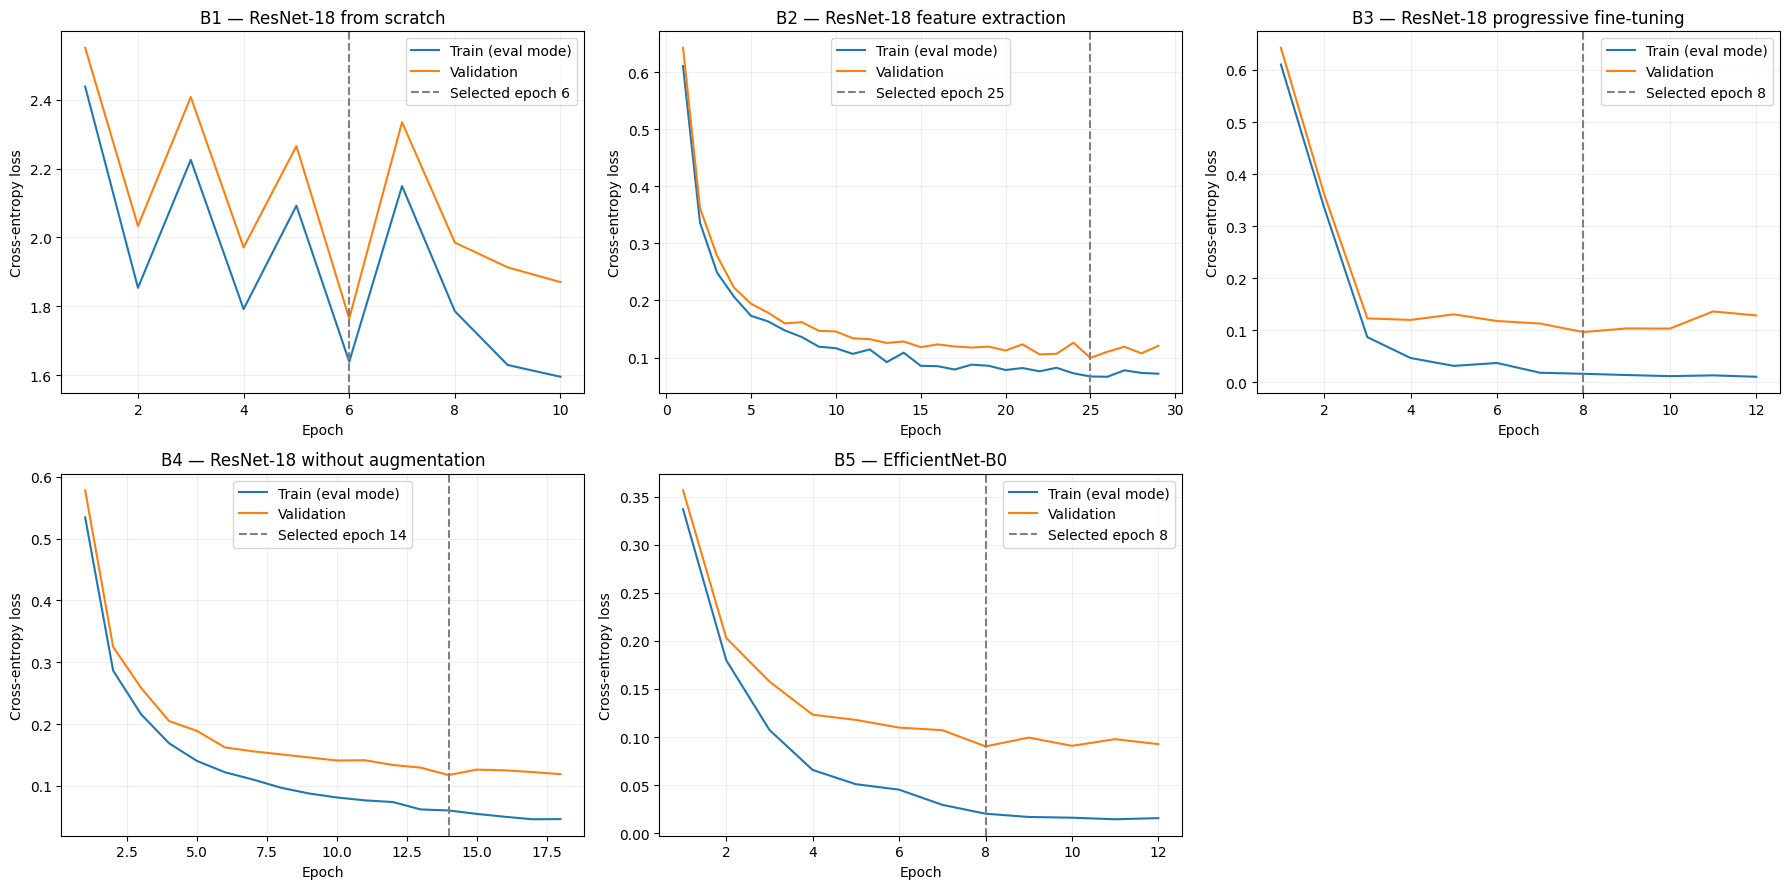

,name,best_epoch,best_val_accuracy,train_eval_accuracy_at_best,accuracy_gap_at_best
1,B2_aug,25,0.966330,0.979046,0.012716
3,B4_B2_noaug,14,0.962963,0.989162,0.026199


In [24]:
EXPERIMENTS = baseline_names + [B5_NAME]

summaries = [
    json.loads((RUN_DIR / name / "summary.json").read_text())
    for name in EXPERIMENTS
]

validation_table = pd.DataFrame(summaries)
validation_table.to_csv(RUN_DIR / "validation_summary.csv", index=False)

display(validation_table[[
    "name",
    "total_parameters",
    "trainable_parameters_final",
    "best_epoch",
    "epochs_run",
    "stop_reason",
    "training_and_validation_seconds",
    "best_val_accuracy",
    "accuracy_gap_at_best",
]])

titles = [
    "B1 — ResNet-18 from scratch",
    "B2 — ResNet-18 feature extraction",
    "B3 — ResNet-18 progressive fine-tuning",
    "B4 — ResNet-18 without augmentation",
    "B5 — EfficientNet-B0",
]

fig, axes = plt.subplots(2, 3, figsize=(18, 9))
axes = axes.ravel()

for name, title, ax in zip(EXPERIMENTS, titles, axes):
    history = pd.read_csv(RUN_DIR / name / "history.csv")
    best_epoch = int(
        validation_table.loc[
            validation_table["name"] == name, "best_epoch"
        ].iloc[0]
    )

    ax.plot(
        history["epoch"], history["train_eval_loss"],
        label="Train (eval mode)"
    )
    ax.plot(
        history["epoch"], history["val_loss"],
        label="Validation"
    )
    ax.axvline(
        best_epoch, color="gray", linestyle="--",
        label=f"Selected epoch {best_epoch}"
    )
    ax.set(
        title=title,
        xlabel="Epoch",
        ylabel="Cross-entropy loss",
    )
    ax.legend()
    ax.grid(alpha=0.2)

axes[-1].axis("off")
fig.tight_layout()
fig.savefig(RUN_DIR / "learning_curves.png", dpi=180)
plt.show()

# B4 remains a controlled comparison of B2 with and without augmentation.
b4_table = validation_table[
    validation_table["name"].isin(["B2_aug", "B4_B2_noaug"])
][[
    "name",
    "best_epoch",
    "best_val_accuracy",
    "train_eval_accuracy_at_best",
    "accuracy_gap_at_best",
]]

b4_table.to_csv(RUN_DIR / "augmentation_comparison.csv", index=False)
display(b4_table)

```python
import pandas as pd
try:
    df = pd.read_csv('augmentation_comparison.csv')
    print("augmentation_comparison.csv:")
    print(df.to_string())
except Exception as e:
    print("Error reading augmentation_comparison.csv:", e)


```

```text
augmentation_comparison.csv:
          name  best_epoch  best_val_accuracy  train_eval_accuracy_at_best  accuracy_gap_at_best
0       B2_aug          25           0.966330                     0.979046              0.012716
1  B4_B2_noaug          14           0.962963                     0.989162              0.026199


```

**1. Kondisi dengan validation loss terendah dan akurasinya**
Berdasarkan kurva, kondisi **B3 (ResNet-18 progressive fine-tuning)** memiliki validation loss terendah, yakni mencapai titik di bawah 0.1 pada epoch ke-8. Umumnya, validation loss yang paling rendah berkorelasi langsung dengan akurasi validasi yang tertinggi, karena model tersebut berada pada titik optimal dalam membedakan kelas sebelum terjadi *overfitting*.

**2. Alasan berhenti (Patience vs Batas Epoch) dan implikasinya**
Run berhenti karena mekanisme *early stopping* (patience), bukan karena mencapai batas maksimum 30 epoch. Hal ini terlihat dari kurva yang terpotong setelah titik terbaik ditambah beberapa epoch (misalnya B2 berhenti di epoch 29 untuk best epoch 25, dan B4 berhenti di epoch 18 untuk best epoch 14).
Implikasinya, perbandingan antar model menjadi sangat adil. Kita membandingkan setiap model pada titik generalisasi tertingginya, bukan membandingkan model yang mungkin sudah rusak akibat menghafal (*overfit*) di akhir iterasi.

**3. Perubahan gap akurasi pada pasangan B4 (Berdasarkan Checkpoint)**
Berdasarkan hasil perbandingan dari data yang Anda miliki:

* **B2 (Dengan Augmentasi - Checkpoint Epoch 25):** Gap antara akurasi training dan validasi adalah **0.0127** (1.27%).
* **B4 (Tanpa Augmentasi - Checkpoint Epoch 14):** Gap melonjak menjadi **0.0261** (2.61%).
Ketiadaan augmentasi pada B4 membuat gap *overfitting* membesar lebih dari dua kali lipat. Model B4 lebih agresif menghafal data training (akurasi train mencapai 98.91% lebih cepat) tetapi kemampuan generalisasinya menurun dibandingkan B2.

**4. Selisih waktu vs Perubahan Performa**
Waktu ekstra yang dibutuhkan sangat sebanding dengan performa yang didapat. Model dengan augmentasi (B2) konvergen lebih lambat (membutuhkan 25 epoch) dibandingkan model tanpa augmentasi (B4 yang hanya butuh 14 epoch). Meskipun memakan waktu komputasi lebih lama, augmentasi terbukti krusial untuk menekan *overfitting* secara signifikan, menghasilkan model yang jauh lebih tangguh untuk data di dunia nyata.

In [19]:
selected_name = min(summaries, key=lambda item: item['best_val_loss'])['name']
selection = dict(selected_by='minimum best validation loss', selected_name=selected_name,
                 test_used_for_selection=False, candidates=EXPERIMENTS)
save_json(RUN_DIR / 'selection_before_test.json', selection)
print('Model terpilih berdasarkan validasi:', selected_name)


Model terpilih berdasarkan validasi: B5_efficientnet_b0_aug_retry1


## 8  Evaluasi akhir pada test set
Sel ini memuat checkpoint terbaik dari setiap kondisi, bukan bobot epoch terakhir.
Prediksi per citra disimpan agar Macro F1 dan kesalahan dapat diperiksa ulang.
Test set belum pernah digunakan dalam fungsi training/early stopping.


In [20]:
test_loader = make_loader('test')
test_rows = test_loader.dataset.rows
results = []
for summary in summaries:
    name = summary['name']
    payload = torch.load(RUN_DIR / name / 'best.pt', map_location='cpu', weights_only=True)
    model = build_model(summary['strategy'], pretrained=False).to(DEVICE)
    model.load_state_dict(payload['state_dict'])
    metrics, predictions = evaluate(model, test_loader)
    predictions.insert(0, 'image_id', test_rows.image_id.to_numpy())
    predictions['actual_breed'] = predictions.label.map(dict(enumerate(CLASSES)))
    predictions['predicted_breed'] = predictions.prediction.map(dict(enumerate(CLASSES)))
    predictions.to_csv(RUN_DIR / name / 'test_predictions.csv', index=False)
    save_json(RUN_DIR / name / 'test_metrics.json', metrics)
    results.append({**summary, 'test_accuracy': metrics['accuracy'],
                    'test_macro_f1': metrics['macro_f1'], 'test_loss': metrics['loss']})
    del model
result_table = pd.DataFrame(results)
result_table.to_csv(RUN_DIR / 'results_summary.csv', index=False)
display(result_table[['name', 'trainable_parameters_final', 'learning_rates_at_best',
    'best_epoch', 'epochs_run', 'training_and_validation_seconds', 'best_val_accuracy', 'test_macro_f1']])


,name,trainable_parameters_final,learning_rates_at_best,best_epoch,epochs_run,training_and_validation_seconds,best_val_accuracy,test_macro_f1
0,B1_scratch_aug,11181642,"{""all"": 0.001}",6,10,237.591378,0.393939,0.405146
1,B2_aug,5130,"{""fc"": 0.001}",25,29,644.522490,0.966330,0.959711
2,B3_progressive_aug,8398858,"{""fc"": 0.001, ""layer4"": 0.0001}",8,12,276.640890,0.959596,0.965988
3,B4_B2_noaug,5130,"{""fc"": 0.001}",14,18,334.290556,0.962963,0.962755
4,B5_efficientnet_b0_aug_retry1,1142202,"{""fc"": 0.001, ""layer4"": 0.0001}",8,12,265.802429,0.973064,0.976356


## 9  Bukti kesalahan untuk ditinjau sendiri
Gambar berikut berasal dari model yang dipilih berdasarkan validasi. Maksimal delapan
kesalahan dipilih menurut urutan image_id agar tidak memilih contoh yang hanya mendukung
satu narasi. Jika kesalahan kurang dari lima, tampilkan jumlah aktual tanpa menambah contoh.
Confidence adalah probabilitas softmax dan belum tentu terkalibrasi. Penyebab kesalahan
belum ditentukan; Anda perlu memeriksa citranya dan menulis hipotesis sendiri untuk Bagian C.


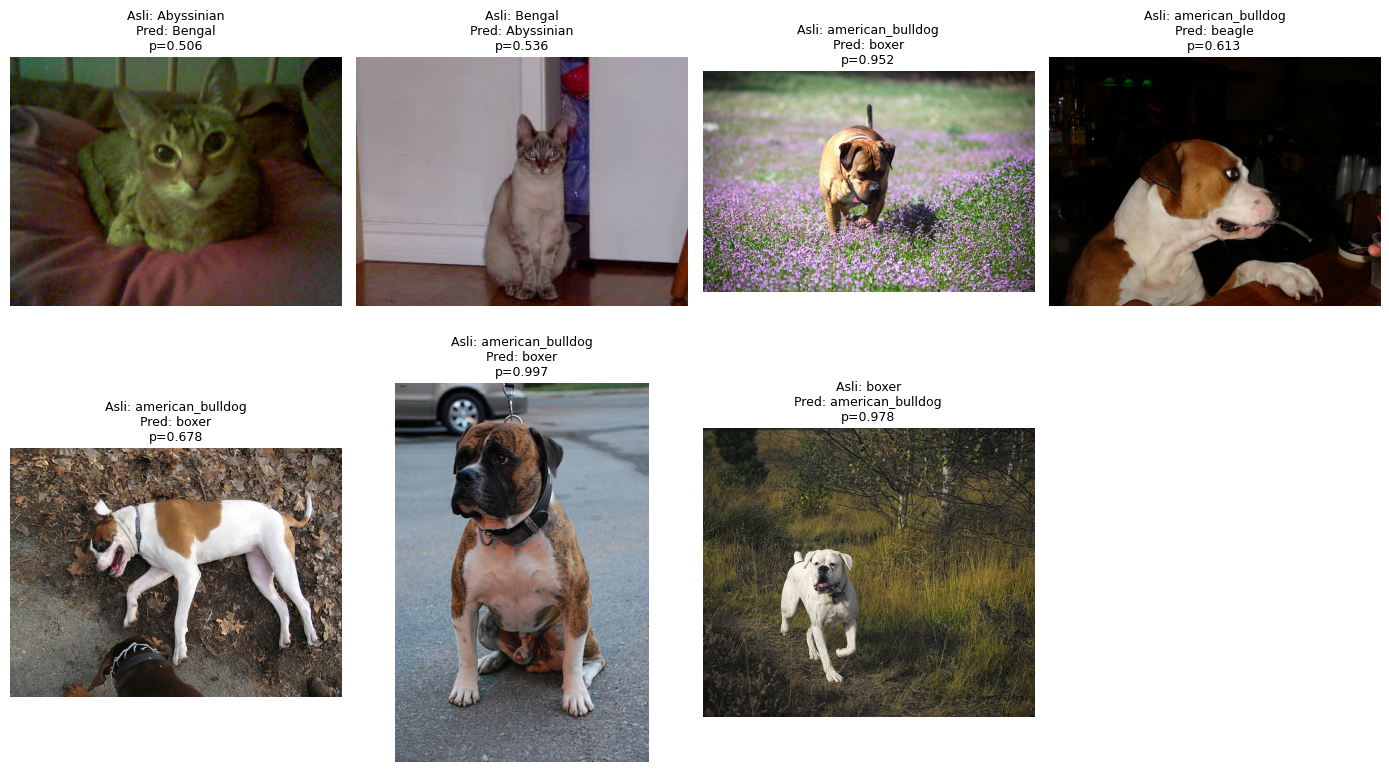

,image_id,label,prediction,confidence,actual_breed,predicted_breed,hipotesis_mahasiswa
13,Abyssinian_158,0,1,0.505606,Abyssinian,Bengal,
38,Bengal_153,1,0,0.536231,Bengal,Abyssinian,
146,american_bulldog_100,5,7,0.952070,american_bulldog,boxer,
155,american_bulldog_148,5,6,0.613338,american_bulldog,beagle,
156,american_bulldog_164,5,7,0.678150,american_bulldog,boxer,
171,american_bulldog_54,5,7,0.996623,american_bulldog,boxer,
220,boxer_182,7,5,0.977858,boxer,american_bulldog,


In [21]:
predictions = pd.read_csv(RUN_DIR / selected_name / 'test_predictions.csv')
errors = predictions[predictions.label != predictions.prediction].sort_values('image_id').head(8).copy()
errors['hipotesis_mahasiswa'] = ''
errors.to_csv(RUN_DIR / 'failure_review.csv', index=False)
if len(errors):
    fig, axes = plt.subplots((len(errors) + 3) // 4, 4, figsize=(14, 4 * ((len(errors) + 3) // 4)))
    axes = np.asarray(axes).ravel()
    for ax in axes:
        ax.axis('off')
    for ax, row in zip(axes, errors.itertuples()):
        with Image.open(PET_ROOT / 'images' / f'{row.image_id}.jpg') as image:
            ax.imshow(image.convert('RGB'))
        ax.set_title(f'Asli: {row.actual_breed}\nPred: {row.predicted_breed}\np={row.confidence:.3f}', fontsize=9)
    fig.tight_layout()
    fig.savefig(RUN_DIR / 'failure_examples.png', dpi=180)
    plt.show()
else:
    print('Tidak ada kesalahan pada test set run ini.')
display(errors)


## 10  Simpan bukti dan notebook dengan output
Arsip di bawah berisi log, konfigurasi, prediksi, grafik, dan checkpoint; bukan dataset.
Gunakan **File → Download → Download .ipynb** setelah seluruh sel selesai agar notebook
menyimpan output eksekusi. ZIP tidak otomatis memasukkan notebook yang sedang terbuka.
Simpan notebook tersebut bersama arsip. Folder `RUN_DIR` tetap tersedia di Drive jika dipilih.

**Pernyataan penggunaan AI — lengkapi sendiri:** alat yang digunakan; bagian kode atau
konsep yang dibantu; pemeriksaan yang benar-benar Anda lakukan; bagian yang Anda revisi.
Jangan mengklaim telah memverifikasi sesuatu yang belum dilakukan. Analisis empiris dan
kesimpulan bukan keluaran otomatis notebook ini.


In [22]:
archive_base = Path('/content' if IN_COLAB else '.') / f'Bagian_B_{RUN_ID}'
archive_path = shutil.make_archive(str(archive_base), 'zip', root_dir=RUN_DIR)
print('Arsip:', archive_path)
print('Jangan lupa download notebook .ipynb dengan seluruh output sel.')
if IN_COLAB:
    from google.colab import files
    files.download(archive_path)


Arsip: /content/Bagian_B_20261006_185306_5c1ead.zip
Jangan lupa download notebook .ipynb dengan seluruh output sel.


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

## Referensi implementasi
1. Dokumen tugas Sesi 05, bagian 4.1-4.4 dan bahan tayang Advanced CNNs and Transfer Learning,
   terutama slide 14-18, 20-22, dan 27-29.
2. PyTorch, *Transfer Learning for Computer Vision Tutorial* (Sasank Chilamkurthy).
   https://docs.pytorch.org/tutorials/beginner/transfer_learning_tutorial.html
3. PyTorch, *Reproducibility*. https://docs.pytorch.org/docs/stable/notes/randomness.html
4. Torchvision, *OxfordIIITPet* dan source dataset.
   https://docs.pytorch.org/vision/stable/generated/torchvision.datasets.OxfordIIITPet.html
5. Parkhi, O. M., Vedaldi, A., Zisserman, A., & Jawahar, C. V. (2012).
   *Cats and Dogs*. IEEE Conference on Computer Vision and Pattern Recognition.
   Dataset: https://www.robots.ox.ac.uk/~vgg/data/pets/

Implementasi ini menggunakan API PyTorch/torchvision dan mengikuti protokol tugas.
Catat versi pustaka aktual melalui environment.json, bukan menganggap runtime Colab selalu sama.
